In [ ]:
import importlib
import Oracle 
import oracle_2
importlib.reload(Oracle)
importlib.reload(oracle_2)
from Oracle import PortfolioOpt
from oracle_2 import PortfolioOpt2
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

In [9]:
import inspect

print(inspect.signature(PortfolioOpt.__init__))

(self, Sigma, r_bar, gamma=1.0)


# Brief description of what we want to do

- We have n available assets.
- We call xi the quantity of money invested on the i-th asset during the
considered period and with ri the returns on the i-th asset.
- We have two different constraints:
    - Non-negativity for the variables (i.e., xi ≥ 0). Meaning that short selling (selling asset that we still don’t own) is not allowed.
    - Budget constraint: $\sum_{i = 1}^{n} = B$, the total amount of money invested needs to be equal to the budget B (B can be simply set to 1).

- $r \in \mathbb{R}^n $ is a randomly generated vector with mean $\hat{r}$ and covariance $\sum$

- Expected return will be $\hat{r}^Tx$ and variance $x^T\sum x$
- Classic portfolio problem, described by Markowits (1952), is a convex quadratic
programming problem:
$$
\begin{aligned}
\min_{x \in \mathbb{R}^n} \quad & \gamma x^\top \Sigma x - \bar{r}^\top x \\
\text{s.t.} \quad & e^\top x = 1 \\
& x \ge 0
\end{aligned}
$$
- with $\gamma > 0$ risk-aversion parameter.
- GOAL: Finding the set of assets that minimises the variance (risk connected to the given portfolio) while maximising the expected return (we obviously need to satisfy budget and non-negativity constraints).

### Load data 

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset_paths = {
    'DowJones': 'DowJones.xlsx',
    'FTSE100': 'FTSE100.xlsx',
    'S&P 500': 'SP500.xlsx'
}

gammas = [0.01, 0.1, 0.5, 1, 5, 10]

methods = ("FW", "ASFW", "PWFW")

initial_budget = 1

all_results = {}

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name='Assets_Returns',
        header=None
    )

    print(f"\nDataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")

    dataset_results = {}

    for gamma in gammas:

        print(f"Running gamma = {gamma}")

        model = PortfolioOpt2(
            data=data,
            window_size=52,
            gamma=gamma
        )

        results = model.rolling_backtest(
            max_iter=10000,
            tol=1e-6,
            forecast_horizon=4,
            methods=methods
        )

        dataset_results[gamma] = results

    all_results[name] = dataset_results


Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10

Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10

Dataset: S&P 500
Number of assets: 442
Number of time periods: 595
Running gamma = 0.01
Running gamma = 0.1
Running gamma = 0.5
Running gamma = 1
Running gamma = 5
Running gamma = 10


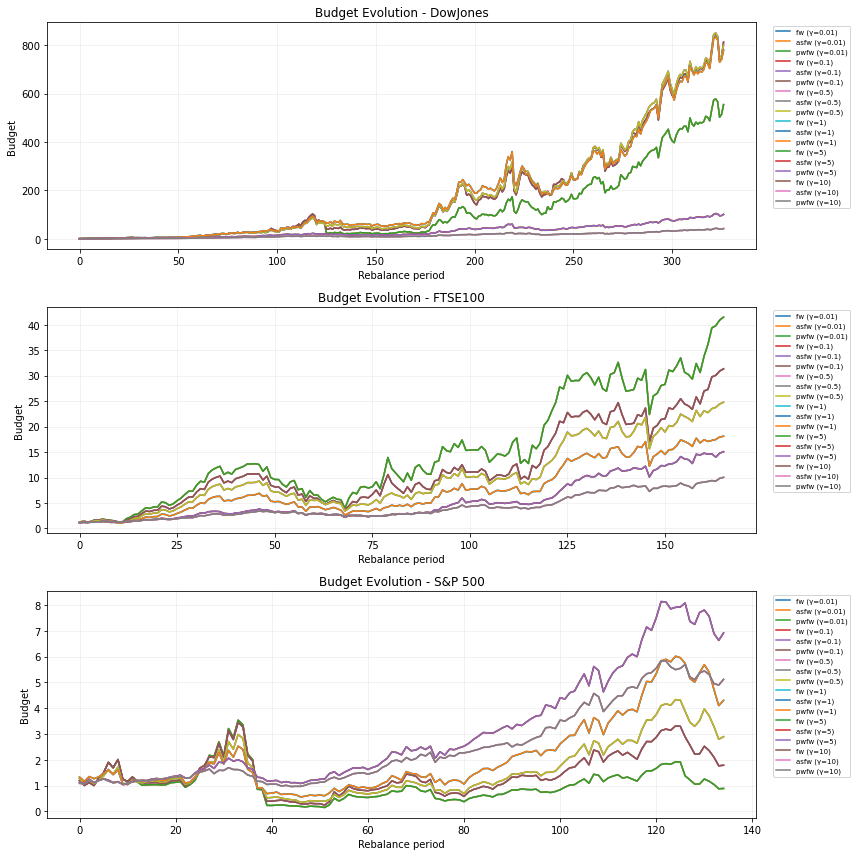

In [ ]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 12)
)

for ax, (dataset_name, dataset_results) in zip(
    axes,
    all_results.items()
):

    for gamma in gammas:

        df = dataset_results[gamma]

        for method in methods:

            # Select method
            method_df = df[
                df["method"] == method
            ].copy()

            method_df = method_df[
                method_df["forecast_horizon"] == 4
            ]

            method_df = method_df.sort_values(
                "rebalance_period"
            )

            ax.plot(
                method_df["rebalance_period"],
                method_df["budget"],
                label=f"{method.lower()} (γ={gamma})"
            )

    ax.set_title(
        f" {dataset_name} - Budget allocation"
    )

    ax.set_xlabel(
        "Rebalance period"
    )

    ax.set_ylabel(
        "Budget"
    )

    ax.grid(
        True,
        alpha=0.2
    )

    ax.legend(
        fontsize=7,
        loc="upper left",
    )

plt.tight_layout()
plt.show()

In [ ]:

)

In [6]:
summary = []

for dataset, results in all_results.items():
    for gamma in gammas:
        df = results[gamma]
        for method in methods:
            final = (
                df[(df["method"] == method) &
                   (df["forecast_horizon"] == 4)]
                ["budget"].iloc[-1]
            )
            summary.append([dataset, gamma, method, final])

summary_df = pd.DataFrame(
    summary,
    columns=["Dataset", "Gamma", "Method", "Final Budget"]
)

print(summary_df.sort_values("Final Budget", ascending=False))

     Dataset  Gamma Method  Final Budget
5   DowJones   0.10   PWFW    812.104080
3   DowJones   0.10     FW    812.036586
4   DowJones   0.10   ASFW    811.482291
6   DowJones   0.50     FW    799.755500
7   DowJones   0.50   ASFW    799.008126
8   DowJones   0.50   PWFW    798.893372
9   DowJones   1.00     FW    779.886487
10  DowJones   1.00   ASFW    778.751638
11  DowJones   1.00   PWFW    778.148979
0   DowJones   0.01     FW    554.358004
1   DowJones   0.01   ASFW    554.358004
2   DowJones   0.01   PWFW    554.358004
12  DowJones   5.00     FW    101.370519
13  DowJones   5.00   ASFW    101.268281
14  DowJones   5.00   PWFW    101.263771
15  DowJones  10.00     FW     42.776871
17  DowJones  10.00   PWFW     42.755485
16  DowJones  10.00   ASFW     42.745890
18   FTSE100   0.01     FW     41.500140
20   FTSE100   0.01   PWFW     41.500140
19   FTSE100   0.01   ASFW     41.500140
22   FTSE100   0.10   ASFW     31.365890
21   FTSE100   0.10     FW     31.355317
23   FTSE100   0

In [ ]:
# ============================================================
# MEAN RETURN, STANDARD DEVIATION AND RISK-ADJUSTED SCORE
# ============================================================

summary = []

for dataset_name, dataset_results in all_results.items():

    for gamma in gammas:

        df = dataset_results[gamma]

        for method in methods:

            method_df = df[
                df["method"] == method
            ].copy()

            returns = method_df["realised_return"]

            mean_return = returns.mean()

            std_return = returns.std()

            if std_return > 0:
                score = mean_return / std_return
            else:
                score = np.nan

            final_budget = method_df["budget"].iloc[-1]

            summary.append({
                "Dataset": dataset_name,
                "Gamma": gamma,
                "Method": method,
                "Mean Return": mean_return,
                "Std Dev": std_return,
                "Risk Adjusted Score": score,
                "Final Budget": final_budget
            })


summary_df = pd.DataFrame(summary)

# Display results
print(
    summary_df.round(6).to_string(index=False)
)

 Dataset  Gamma Method  Mean Return  Std Dev  Risk Adjusted Score  Final Budget
DowJones   0.01     FW     0.006316 0.052869             0.119468    554.358004
DowJones   0.01   ASFW     0.006316 0.052869             0.119468    554.358004
DowJones   0.01   PWFW     0.006316 0.052869             0.119468    554.358004
DowJones   0.10     FW     0.006444 0.050889             0.126626    812.036586
DowJones   0.10   ASFW     0.006443 0.050891             0.126614    811.482291
DowJones   0.10   PWFW     0.006444 0.050888             0.126628    812.104080
DowJones   0.50     FW     0.006268 0.047769             0.131215    799.755500
DowJones   0.50   ASFW     0.006267 0.047768             0.131201    799.008126
DowJones   0.50   PWFW     0.006267 0.047768             0.131199    798.893372
DowJones   1.00     FW     0.006139 0.045401             0.135223    779.886487
DowJones   1.00   ASFW     0.006138 0.045403             0.135196    778.751638
DowJones   1.00   PWFW     0.006138 0.04

In [6]:
# ============================================================
# BEST METHOD + GAMMA FOR EACH DATASET
# ============================================================

best_results = (
    summary_df
    .sort_values(
        ["Dataset", "Risk Adjusted Score"],
        ascending=[True, False]
    )
    .groupby("Dataset")
    .first()
    .reset_index()
)

print("\n==============================================")
print("BEST RISK-ADJUSTED RESULTS")
print("==============================================")

print(
    best_results[
        [
            "Dataset",
            "Gamma",
            "Method",
            "Mean Return",
            "Std Dev",
            "Risk Adjusted Score",
            "Final Budget"
        ]
    ].round(6).to_string(index=False)
)


BEST RISK-ADJUSTED RESULTS
 Dataset  Gamma Method  Mean Return  Std Dev  Risk Adjusted Score  Final Budget
DowJones    1.0     FW     0.006139 0.045401             0.135223    779.886487
 FTSE100   10.0   PWFW     0.003814 0.025789             0.147890     10.047097
   SP500    5.0   PWFW     0.004335 0.038600             0.112317      6.921917


In [16]:
dataset_paths = {
    'DowJones': 'DowJones.xlsx', 
    'FTSE100': 'FTSE100.xlsx',
    'S&P500': 'SP500.xlsx'
}

all_results = {}
summary_list = []

for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    r_bar = data.mean().values
    Sigma = data.cov().values
    print(f"Dataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")
    
    model = PortfolioOpt(Sigma=Sigma, r_bar=r_bar, gamma =0.01)

    results = model.run_all_fw(max_iter=10000, tol=1e-6)
    all_results[name] = results

    for variant, result in results.items():
        history = result['history']
        summary_list.append({
            'Dataset': name,
            'Algorithm': variant,
            'Num Assets (n)': data.shape[1],
            'Time Periods (T)': data.shape[0],
            'Iterations': len(history),
            'Final Objective': history['objective'].iloc[-1],
            'Final Duality Gap': history['gap'].iloc[-1],
            'Active Size (final)': history['active_size'].iloc[-1],
            'Time (s)': result['time']
        })

    
summary_df = pd.DataFrame(summary_list)
print("\n" + summary_df.to_string(index=False))

Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Dataset: S&P500
Number of assets: 442
Number of time periods: 595

 Dataset Algorithm  Num Assets (n)  Time Periods (T)  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
DowJones        FW              28              1363           2        -0.006020               -0.0                    1  0.001992
DowJones      ASFW              28              1363           2        -0.006020               -0.0                    1  0.000996
DowJones      PWFW              28              1363           2        -0.006020               -0.0                    1  0.000000
 FTSE100        FW              83               717           2        -0.007953               -0.0                    1  0.000000
 FTSE100      ASFW              83               717           2        -0.007953               -0.0                    1  0.001000
 FTSE10

In [10]:
import pandas as pd

dataset_paths = {
    'DowJones': 'DowJones.xlsx',
    'FTSE100': 'FTSE100.xlsx',
    'S&P500': 'SP500.xlsx'
}

selected_gammas = {
    'DowJones': 0.10,
    'FTSE100': 0.01,
    'S&P500': 5.00
}

methods = ("FW", "ASFW", "PWFW")

summary = []

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name='Assets_Returns',
        header=None
    )

    model = PortfolioOpt2(
        data=data,
        window_size=52,
        gamma=selected_gammas[name]
    )

    backtest = model.rolling_backtest(
        max_iter=10000,
        tol=1e-6,
        forecast_horizon=4,
        methods=methods
    )

    first_window = backtest[backtest['window'] == 0]

    for method in methods:

        df = first_window[first_window['method'] == method]

        summary.append({
            'Dataset': name,
            'Gamma': selected_gammas[name],
            'Algorithm': method,
            'Iterations': df['iterations'].iloc[0],
            'Runtime (s)': df['runtime'].iloc[0],
            'Objective': df['objective'].iloc[0],
            'Final Gap': df['final_gap'].iloc[0],
            'Active Assets': df['active_assets'].iloc[0]
        })

summary_df = pd.DataFrame(summary)

print(summary_df.to_string(index=False))

 Dataset  Gamma Algorithm  Iterations  Runtime (s)  Objective     Final Gap  Active Assets
DowJones   0.10        FW           2     0.000994  -0.025106 -0.000000e+00              1
DowJones   0.10      ASFW           2     0.000997  -0.025106 -0.000000e+00              1
DowJones   0.10      PWFW           2     0.000997  -0.025106 -0.000000e+00              1
 FTSE100   0.01        FW           2     0.000000  -0.020141 -0.000000e+00              1
 FTSE100   0.01      ASFW           2     0.000998  -0.020141 -0.000000e+00              1
 FTSE100   0.01      PWFW           2     0.000000  -0.020141 -0.000000e+00              1
  S&P500   5.00        FW       10000     1.168937  -0.020809  4.446658e-06             10
  S&P500   5.00      ASFW          40     0.029593  -0.020810  8.590250e-07              9
  S&P500   5.00      PWFW          30     0.003414  -0.020810  7.887958e-07              9


In [ ]:
import pandas as pd

dataset_paths = {
    'DowJones': 'DowJones.xlsx', 
    'FTSE100': 'FTSE100.xlsx',
    'S&P500': 'SP500.xlsx'
}

all_results = {}
summary_list = []
TARGET_OBSERVATIONS = 595

for name, path in dataset_paths.items():
    raw_data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)
    data = raw_data.tail(TARGET_OBSERVATIONS)
    
    r_bar = data.mean().values
    Sigma = data.cov().values
    
    print(f"\n--- Dataset: {name} ---")
    print(f"Number of assets (n): {data.shape[1]}")
    print(f"Number of time periods (T): {data.shape[0]} (aligned)")
    
    model = PortfolioOpt(Sigma=Sigma, r_bar=r_bar, gamma=1)

    results = model.run_all_fw(max_iter=10000, tol=1e-6)
    all_results[name] = results

    for variant, result in results.items():
        history = result['history']
        get_last = lambda key: history[key].iloc[-1] if isinstance(history[key], (pd.Series, pd.DataFrame)) else history[key][-1]
        
        summary_list.append({
            'Dataset': name,
            'Algorithm': variant,
            'Num Assets (n)': data.shape[1],
            'Time Periods (T)': data.shape[0],
            'Iterations': len(history['objective']) if isinstance(history, dict) else len(history),
            'Final Objective': get_last('objective'),
            'Final Duality Gap': get_last('gap'),
            'Active Size (final)': get_last('active_size'),
            'Time (s)': result['time']
        })

summary_df = pd.DataFrame(summary_list)

with pd.option_context('display.max_columns', None, 'display.width', 1000):
    print("\n=== Standardized Portfolio Optimization Results (T = 595) ===")
    print(summary_df.to_string(index=False))


--- Dataset: DowJones ---
Number of assets (n): 28
Number of time periods (T): 595 (aligned)

--- Dataset: FTSE100 ---
Number of assets (n): 83
Number of time periods (T): 595 (aligned)

--- Dataset: S&P500 ---
Number of assets (n): 442
Number of time periods (T): 595 (aligned)

=== Standardized Portfolio Optimization Results (T = 595) ===
 Dataset Algorithm  Num Assets (n)  Time Periods (T)  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
DowJones        FW              28               595           2        -0.004419      -6.776264e-20                    2  0.000000
DowJones      ASFW              28               595           2        -0.004419      -6.776264e-20                    2  0.000000
DowJones      PWFW              28               595           2        -0.004419      -6.776264e-20                    2  0.000000
 FTSE100        FW              83               595        2698        -0.004434       9.788012e-07                    9  0.1434

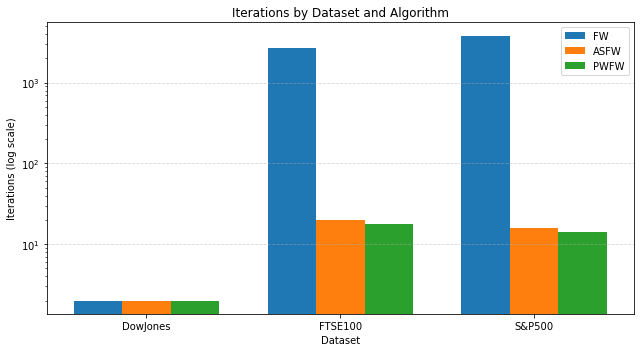

In [12]:
import numpy as np
import matplotlib.pyplot as plt

algorithms = ["FW", "ASFW", "PWFW"]
datasets = summary_df["Dataset"].unique()

x = np.arange(len(datasets))
width = 0.25

plt.figure(figsize=(9, 5))

for i, algorithm in enumerate(algorithms):

    subset = summary_df[
        summary_df["Algorithm"] == algorithm
    ].set_index("Dataset")

    values = subset.reindex(datasets)["Iterations"]

    plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=algorithm
    )

plt.yscale("log")

plt.xlabel("Dataset")
plt.ylabel("Iterations (log scale)")
plt.title("Iterations by Dataset and Algorithm")
plt.xticks(x, datasets)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [17]:
for name, path in dataset_paths.items():
    data = pd.read_excel(path, sheet_name='Assets_Returns', header=None)

    r_bar = data.mean().values
    Sigma = data.cov().values

    model = PortfolioOpt(Sigma=Sigma, r_bar=r_bar, gamma=0.01)

    results = model.run_all_fw(max_iter=1000, tol=1e-6)

    asset_names = list(data.columns)

    print(f"\n{'='*60}")
    print(f"Dataset: {name}")

    for variant, result in results.items():

        x_final = result['x']

        active = np.where(np.abs(x_final) > 1e-8)[0]

        print(f"\n{variant}")
        print(f"Number of active assets: {len(active)}")

        for i in active:
            print(f"  {asset_names[i]}: {x_final[i]:.6f}")


Dataset: DowJones

FW
Number of active assets: 1
  17: 1.000000

ASFW
Number of active assets: 1
  17: 1.000000

PWFW
Number of active assets: 1
  17: 1.000000

Dataset: FTSE100

FW
Number of active assets: 1
  77: 1.000000

ASFW
Number of active assets: 1
  77: 1.000000

PWFW
Number of active assets: 1
  77: 1.000000

Dataset: S&P500

FW
Number of active assets: 1
  86: 1.000000

ASFW
Number of active assets: 1
  86: 1.000000

PWFW
Number of active assets: 1
  86: 1.000000


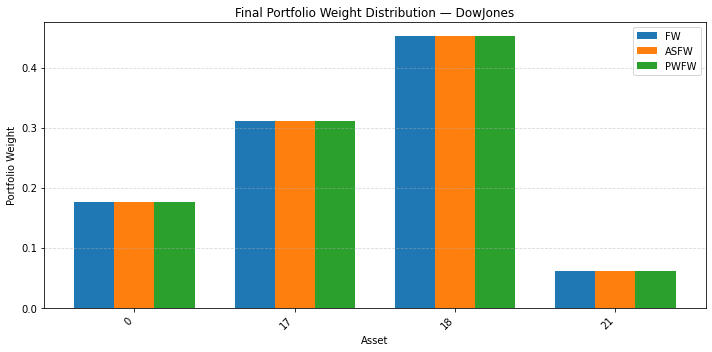

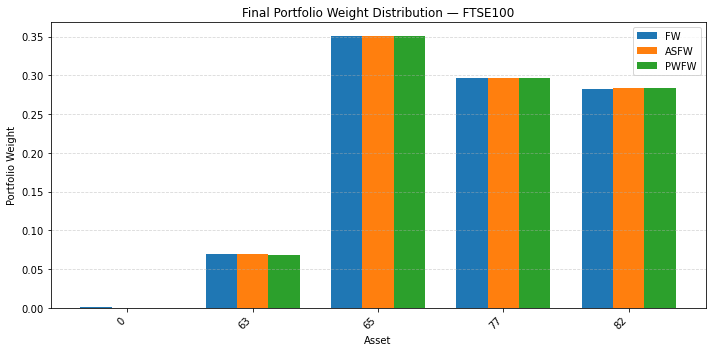

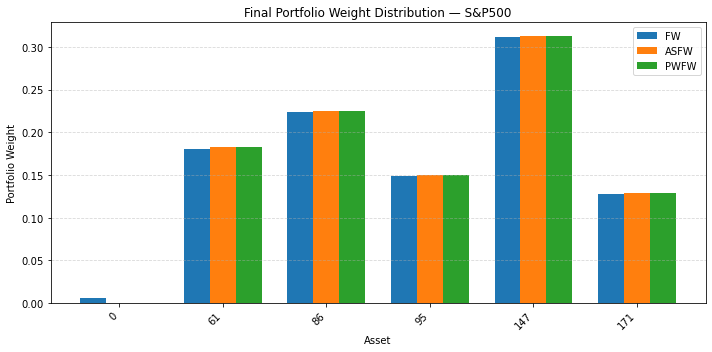

In [11]:
for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name='Assets_Returns',
        header=None
    )

    r_bar = data.mean().values
    Sigma = data.cov().values

    model = PortfolioOpt(
        Sigma=Sigma,
        r_bar=r_bar,
        gamma=1
    )

    results = model.run_all_fw(
        max_iter=1000,
        tol=1e-6
    )

    asset_names = list(data.columns)

    algorithms = ["FW", "ASFW", "PWFW"]

    active_assets = set()

    for algorithm in algorithms:
        x_final = results[algorithm]["x"]
        active = np.where(np.abs(x_final) > 1e-8)[0]
        active_assets.update(active)

    active_assets = sorted(active_assets)

    x = np.arange(len(active_assets))
    width = 0.25

    plt.figure(figsize=(10, 5))

    for i, algorithm in enumerate(algorithms):

        weights = results[algorithm]["x"][active_assets]

        plt.bar(
            x + (i - 1) * width,
            weights,
            width,
            label=algorithm
        )

    plt.xlabel("Asset")
    plt.ylabel("Portfolio Weight")
    plt.title(f"Final Portfolio Weight Distribution — {name}")
    plt.xticks(
        x,
        [asset_names[i] for i in active_assets],
        rotation=45,
        ha="right"
    )
    plt.legend()
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

In [30]:
print("\n" + "="*100)
print("PERFORMANCE SUMMARY")
print("="*100)

for dataset in summary_df['Dataset'].unique():
    print(f"\n{'='*40}")
    print(f"DATASET: {dataset}")
    print(f"{'='*40}")
    
    df_subset = summary_df[summary_df['Dataset'] == dataset]
    
    best_obj = df_subset.loc[df_subset['Final Objective'].idxmin()]
    print(f"\nBest Final Objective: {best_obj['Algorithm']} ({best_obj['Final Objective']:.6f})")
    
    sparsest = df_subset.loc[df_subset['Active Size (final)'].idxmin()]
    print(f"Sparsest Solution: {sparsest['Algorithm']} (Active: {sparsest['Active Size (final)']:.0f} assets)")
    
    fastest = df_subset.loc[df_subset['Time (s)'].idxmin()]
    print(f"Fastest: {fastest['Algorithm']} ({fastest['Time (s)']:.3f}s)")
    
    print("\nDetailed Results:")
    print(df_subset[['Algorithm', 'Iterations', 'Final Objective', 'Final Duality Gap', 
                     'Active Size (final)', 'Time (s)']].to_string(index=False))


PERFORMANCE SUMMARY

DATASET: DowJones

Best Final Objective: PGD (-0.004183)
Sparsest Solution: FW (Active: 4 assets)
Fastest: ASFW (0.001s)

Detailed Results:
Algorithm  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
       FW          29        -0.004183       9.447384e-07                    4  0.003000
     ASFW           9        -0.004183       6.307742e-08                    4  0.000999
     PWFW          13        -0.004183       3.594216e-07                    4  0.000999
      PGD         102        -0.004183       7.774564e-09                    4  0.006484

DATASET: FTSE100

Best Final Objective: PGD (-0.005240)
Sparsest Solution: ASFW (Active: 4 assets)
Fastest: ASFW (0.001s)

Detailed Results:
Algorithm  Iterations  Final Objective  Final Duality Gap  Active Size (final)  Time (s)
       FW        1000        -0.005238       4.719538e-06                    5  0.111837
     ASFW          11        -0.005240       3.355678e-07                

In [31]:
# Compare algorithms relative to PGD
print("\n" + "="*100)
print("RELATIVE PERFORMANCE COMPARISON (vs PGD)")
print("="*100)

for dataset in summary_df['Dataset'].unique():
    print(f"\n{dataset}:")
    pgd_row = summary_df[(summary_df['Dataset'] == dataset) & (summary_df['Algorithm'] == 'PGD')].iloc[0]
    
    for algo in ['FW', 'ASFW', 'PWFW']:
        algo_row = summary_df[(summary_df['Dataset'] == dataset) & (summary_df['Algorithm'] == algo)].iloc[0]
        
        obj_diff = (algo_row['Final Objective'] - pgd_row['Final Objective']) / abs(pgd_row['Final Objective']) * 100
        speedup = pgd_row['Time (s)'] / algo_row['Time (s)']
        sparsity_improvement = (pgd_row['Active Size (final)'] - algo_row['Active Size (final)']) / pgd_row['Active Size (final)'] * 100
        
        print(f"  {algo}:")
        print(f"    Objective diff: {obj_diff:.4f}% vs PGD")
        print(f"    Speedup: {speedup:.2f}x faster")
        print(f"    Sparsity improvement: {sparsity_improvement:.1f}% fewer assets")
        print(f"    Iterations: {algo_row['Iterations']} (vs {pgd_row['Iterations']} for PGD)")


RELATIVE PERFORMANCE COMPARISON (vs PGD)

DowJones:
  FW:
    Objective diff: 0.0000% vs PGD
    Speedup: 2.16x faster
    Sparsity improvement: 0.0% fewer assets
    Iterations: 29 (vs 102 for PGD)
  ASFW:
    Objective diff: 0.0000% vs PGD
    Speedup: 6.49x faster
    Sparsity improvement: 0.0% fewer assets
    Iterations: 9 (vs 102 for PGD)
  PWFW:
    Objective diff: 0.0000% vs PGD
    Speedup: 6.49x faster
    Sparsity improvement: 0.0% fewer assets
    Iterations: 13 (vs 102 for PGD)

FTSE100:
  FW:
    Objective diff: 0.0491% vs PGD
    Speedup: 0.22x faster
    Sparsity improvement: -25.0% fewer assets
    Iterations: 1000 (vs 310 for PGD)
  ASFW:
    Objective diff: 0.0000% vs PGD
    Speedup: 24.14x faster
    Sparsity improvement: 0.0% fewer assets
    Iterations: 11 (vs 310 for PGD)
  PWFW:
    Objective diff: 0.0000% vs PGD
    Speedup: 22.54x faster
    Sparsity improvement: 0.0% fewer assets
    Iterations: 12 (vs 310 for PGD)

SP500:
  FW:
    Objective diff: 0.0327% 

In [32]:
metrics = ['Final Objective', 'Time (s)', 'Active Size (final)']
ranking_df = summary_df.copy()

for metric in metrics:
    ranking_df[f'{metric}_Rank'] = ranking_df.groupby('Dataset')[metric].rank()

ranking_df['Overall_Rank'] = ranking_df[[f'{m}_Rank' for m in metrics]].mean(axis=1)

print("\n" + "="*100)
print("ALGORITHM RANKING (lower is better)")
print("="*100)
for dataset in ranking_df['Dataset'].unique():
    print(f"\n{dataset}:")
    subset = ranking_df[ranking_df['Dataset'] == dataset].sort_values('Overall_Rank')
    print(subset[['Algorithm', 'Overall_Rank', 'Final Objective', 'Time (s)', 'Active Size (final)']].to_string(index=False))


ALGORITHM RANKING (lower is better)

DowJones:
Algorithm  Overall_Rank  Final Objective  Time (s)  Active Size (final)
     ASFW      2.000000        -0.004183  0.000999                    4
     PWFW      2.333333        -0.004183  0.000999                    4
      PGD      2.500000        -0.004183  0.006484                    4
       FW      3.166667        -0.004183  0.003000                    4

FTSE100:
Algorithm  Overall_Rank  Final Objective  Time (s)  Active Size (final)
     ASFW      1.666667        -0.005240  0.001041                    4
      PGD      2.000000        -0.005240  0.025127                    4
     PWFW      2.333333        -0.005240  0.001115                    4
       FW      4.000000        -0.005238  0.111837                    5

SP500:
Algorithm  Overall_Rank  Final Objective  Time (s)  Active Size (final)
     PWFW      1.333333        -0.007494  0.001075                    5
     ASFW      2.333333        -0.007494  0.002059                    

# Convergence Rate

## Standard FW:

On small problems (DowJones, $n=28$), standard FW converges relatively quickly (29 iterations).

On larger dimensions (FTSE100, $n=83$ and S&P 500, $n=442$), standard FW hits the maximum iteration limit of 1000 without reaching a duality gap below $10^{-6}$.

It can only add weight to a new vertex and dilute the rest  ($x_{t+1} = (1-\gamma)x_t + \gamma s_t$) but it cannot directly subtract weight from bad vertices. 

This, in turn causes severe "zig-zagging" near the boundaries of the simplex, leading to a slow sublinear convergence rate $\mathcal{O}(1/k)$.

## Away step FW:

Converges rapidly across datasets (9 for DowJones, 11 for FTSE100 and 16 for SP500).

This works as it can choose an away step which means that it reduces weight from the worst active asset in the current portfolio.

## Pairwise FW:

Converges rapidly across datasets (13 for DowJones, 12 for FTSE100 and 14 for SP500).

It moves weight directly from the worst active asset to the best candidate asset in a single step avoiding non - progressing drop steps

# Objective Value

For FTSE100 and S&P 500, ASFW and PWFW find a strictly lower (better) objective value ( -0.005240 vs. -0.005238 on FTSE100, and -0.007494 vs. -0.007492 on S&P 500).

Standard FW got stuck in the tail end of its sublinear phase, whereas ASFW and PWFW quickly reached the true constrained optimum.

# Final active set size

All three algorithms identify a highly sparse optimal portfolio:

- DowJones ($n=28$): Optimal portfolio relies on only 4 assets.
- FTSE100 ($n=83$): Optimal portfolio relies on 4 assets (FW retains 5 due to premature termination).
- S&P 500 ($n=442$): Out of 442 available stocks, the Markowitz optimal allocation uses only 5 assets.

# Execution Time

PWFW and ASFW are much faster in execution time than standard FW on large dimensions (SP 500 takes ~0.002s for PWFW vs. ~0.242s for FW).

Because total execution time is dominated by matrix-vector multiplications ($\Sigma x_t$), running 14–16 iterations instead of 1000 leads to massive speedups.



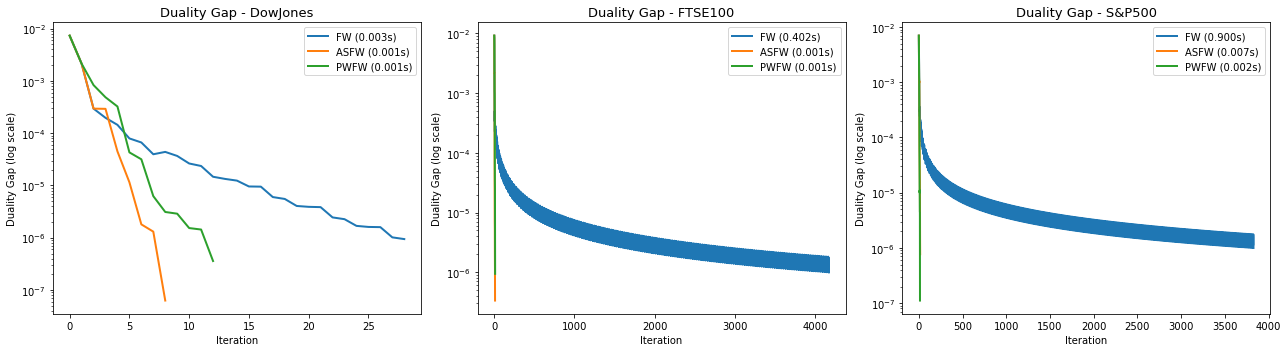

In [9]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (name, results) in enumerate(all_results.items()):
    ax = axes[idx]
    for variant, res in results.items():
        history = res['history']
        if 'gap' in history.columns and not history['gap'].isna().all():
            ax.semilogy(
                history['iter'],
                history['gap'],
                label=f"{variant} ({res['time']:.3f}s)",
                linewidth=2
            )
    ax.set_title(f'Duality Gap - {name}', fontsize=13)
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Duality Gap (log scale)')
    ax.legend()
plt.tight_layout()
plt.show()


<Figure size 720x432 with 0 Axes>

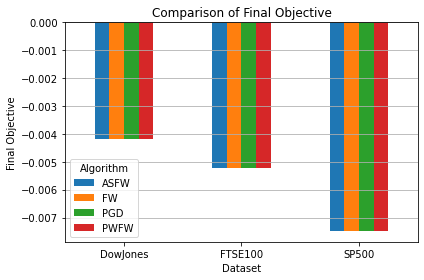

<Figure size 720x432 with 0 Axes>

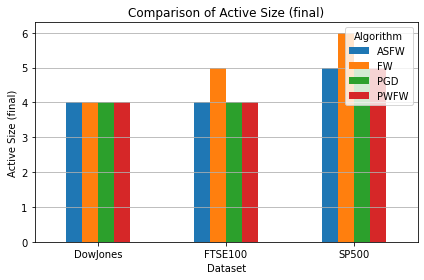

<Figure size 720x432 with 0 Axes>

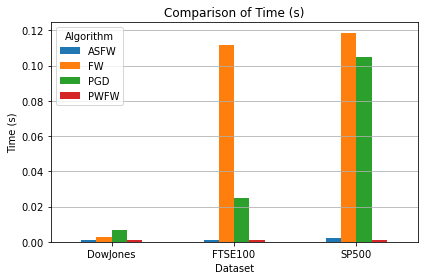

In [34]:
metrics = ['Final Objective', 'Active Size (final)', 'Time (s)']
for metric in metrics:
    plt.figure(figsize=(10, 6))
    pivot = summary_df.pivot(index='Dataset', columns='Algorithm', values=metric)
    pivot.plot(kind='bar', rot=0)
    plt.title(f'Comparison of {metric}')
    plt.ylabel(metric)
    plt.legend(title='Algorithm')
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()

NameError: name 'reference_objectives' is not defined

In [36]:
import time

operation_times = []

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name="Assets_Returns",
        header=None
    )

    r_bar = data.mean().values
    Sigma = data.cov().values

    model = PortfolioOpt(
        Sigma=Sigma,
        r_bar=r_bar,
        gamma=1
    )

    x = np.ones(model.n) / model.n

    grad = model.gradient(x)

    y = x - 0.1 * grad

    repetitions = 10000

    # LMO
    start = time.time()

    for _ in range(repetitions):
        s_idx = np.argmin(grad)

    lmo_time = (time.time() - start) / repetitions


    # Projection
    start = time.time()

    for _ in range(repetitions):
        projected = model.project_simplex(y)

    projection_time = (time.time() - start) / repetitions


    operation_times.append({
        "Dataset": name,
        "Num Assets": model.n,
        "LMO Time": lmo_time,
        "Projection Time": projection_time,
        "Projection / LMO": projection_time / lmo_time
    })

operation_times_df = pd.DataFrame(operation_times)

operation_times_df

,Dataset,Num Assets,LMO Time,Projection Time,Projection / LMO
0,DowJones,28,0.000002,0.000025,11.210595
1,FTSE100,83,0.000002,0.000018,8.446477
2,SP500,442,0.000003,0.000035,11.196538


In [1]:
plt.figure(figsize=(8,5))

plt.plot(
    operation_times_df["Dataset"],
    operation_times_df["Projection / LMO"],
    marker="o"
)

plt.xlabel("Dataset")
plt.ylabel("Projection time / LMO time")
plt.title("Relative Cost of Simplex Projection vs LMO")
plt.grid(True)

plt.show()

NameError: name 'plt' is not defined

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis


# ============================================================
# SETTINGS
# ============================================================

dataset_paths = {
    'DowJones': 'DowJones.xlsx',
    'FTSE100': 'FTSE100.xlsx',
    'S&P 500': 'SP500.xlsx'
}

EDA_DIR = "eda_results"
os.makedirs(EDA_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")


# ============================================================
# LOAD DATASETS
# ============================================================

datasets = {}

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name='Assets_Returns',
        header=None
    )

    # Make sure all values are numeric
    data = data.apply(pd.to_numeric, errors='coerce')

    # Remove completely empty rows/columns
    data = data.dropna(axis=0, how='all')
    data = data.dropna(axis=1, how='all')

    # IMPORTANT: store the dataset
    datasets[name] = data

    print(f"\nDataset: {name}")
    print(f"Number of assets: {data.shape[1]}")
    print(f"Number of time periods: {data.shape[0]}")
    print(f"Missing values: {data.isna().sum().sum()}")


# ============================================================
# DATASET SUMMARY
# ============================================================

dataset_summary = []

for name, data in datasets.items():

    # Flatten all asset returns into one vector
    values = data.values.flatten()

    # Remove NaN and infinite values
    values = values[np.isfinite(values)]

    dataset_summary.append({
        'Dataset': name,
        'Assets (N)': data.shape[1],
        'Time Periods (T)': data.shape[0],
        'Total Observations': data.size,
        'Missing Values': data.isna().sum().sum(),
        'Mean Return': np.mean(values),
        'Median Return': np.median(values),
        'Std Return': np.std(values, ddof=1),
        'Minimum Return': np.min(values),
        'Maximum Return': np.max(values),
        'Skewness': skew(values),
        'Kurtosis': kurtosis(values)
    })


# Convert to DataFrame
dataset_summary_df = pd.DataFrame(dataset_summary)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 100)
print("DATASET SUMMARY")
print("=" * 100)

print(
    dataset_summary_df.to_string(index=False)
)


# ============================================================
# SAVE RESULTS
# ============================================================

dataset_summary_df.to_csv(
    f"{EDA_DIR}/dataset_summary.csv",
    index=False
)

print("\nSummary saved to:")
print(f"{EDA_DIR}/dataset_summary.csv")


Dataset: DowJones
Number of assets: 28
Number of time periods: 1363
Missing values: 0

Dataset: FTSE100
Number of assets: 83
Number of time periods: 717
Missing values: 0

Dataset: SP500
Number of assets: 442
Number of time periods: 595
Missing values: 0

DATASET SUMMARY
 Dataset  Assets (N)  Time Periods (T)  Total Observations  Missing Values  Mean Return  Median Return  Std Return  Minimum Return  Maximum Return  Skewness  Kurtosis
DowJones          28              1363               38164               0     0.002885       0.002198    0.041912       -0.546737        0.452201  0.028168  5.689745
 FTSE100          83               717               59511               0     0.002508       0.002595    0.046681       -0.798225        0.805270  0.348390 18.383615
   SP500         442               595              262990               0     0.002546       0.002337    0.049031       -0.790861        1.371438  0.902660 21.747128

Summary saved to:
eda_results/dataset_summary.csv


In [ ]:

asset_return_stats = []

for name, data in datasets.items():

    average_returns = data.mean(axis=0, skipna=True)


    asset_return_stats.append({
        'Dataset': name,
        'Number of Assets': len(average_returns),
        'Mean Average Return': average_returns.mean(),
        'Median Average Return': average_returns.median(),
        'Std Average Return': average_returns.std(ddof=1),
        'Minimum Average Return': average_returns.min(),
        'Maximum Average Return': average_returns.max(),
        'Skewness': skew(average_returns),
        'Kurtosis': kurtosis(average_returns)
    })


asset_return_stats_df = pd.DataFrame(asset_return_stats)



DESCRIPTIVE STATISTICS OF AVERAGE ASSET RETURNS
 Dataset  Number of Assets  Mean Average Return  Median Average Return  Std Average Return  Minimum Average Return  Maximum Average Return  Skewness  Kurtosis
DowJones                28             0.002885               0.002506            0.001258                0.001278                0.006054  1.288624  0.671913
 FTSE100                83             0.002508               0.002507            0.001506               -0.000610                0.008018  0.807218  1.337827
   SP500               442             0.002546               0.002339            0.001471               -0.000626                0.010325  1.499171  4.517561

Statistics saved to:
eda_results/average_asset_return_statistics.csv


In [ ]:
asset_statistics = []

for name, data in datasets.items():

    for asset in data.columns:

        returns = data[asset].dropna().values

        returns = returns[np.isfinite(returns)]

        if len(returns) == 0:
            continue

        asset_statistics.append({
            'Dataset': name,
            'Asset': asset,
            'Observations': len(returns),
            'Mean Return': np.mean(returns),
            'Median Return': np.median(returns),
            'Std Return': np.std(returns, ddof=1),
            'Minimum Return': np.min(returns),
            'Maximum Return': np.max(returns),
            'Skewness': skew(returns),
            'Kurtosis': kurtosis(returns)
        })

asset_statistics_df = pd.DataFrame(asset_statistics)

print("\n" + "=" * 120)
print("DESCRIPTIVE STATISTICS FOR EACH ASSET")
print("=" * 120)

print(asset_statistics_df.to_string(index=False))


LOADING DATASETS

DowJones
--------------------------------------------------
Assets (N):       28
Time periods (T): 1363
Observations:     38164
Missing values:   0

FTSE100
--------------------------------------------------
Assets (N):       83
Time periods (T): 717
Observations:     59511
Missing values:   0

S&P 500
--------------------------------------------------
Assets (N):       442
Time periods (T): 595
Observations:     262990
Missing values:   0


DATASET SUMMARY
 Dataset  Assets (N)  Time Periods (T)  Total Observations  Missing Values  Mean Return  Median Return  Std Return  Minimum Return  Maximum Return  Skewness  Kurtosis
DowJones          28              1363               38164               0     0.002885       0.002198    0.041912       -0.546737        0.452201  0.028168  5.689745
 FTSE100          83               717               59511               0     0.002508       0.002595    0.046681       -0.798225        0.805270  0.348390 18.383615
 S&P 500         44

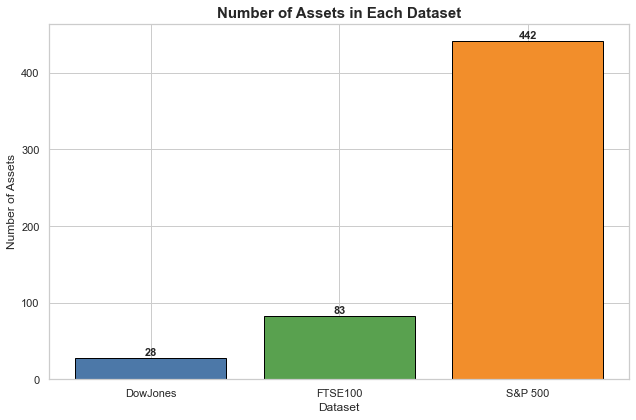

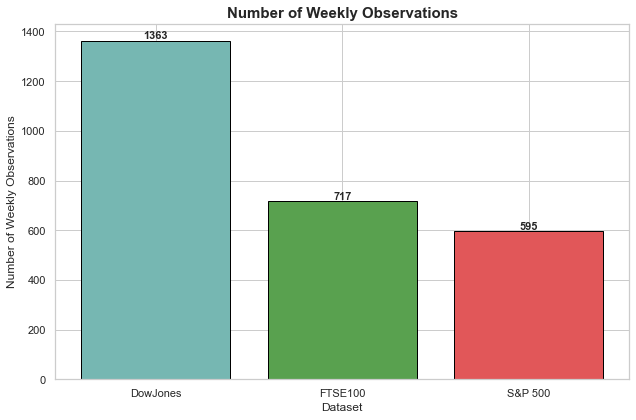

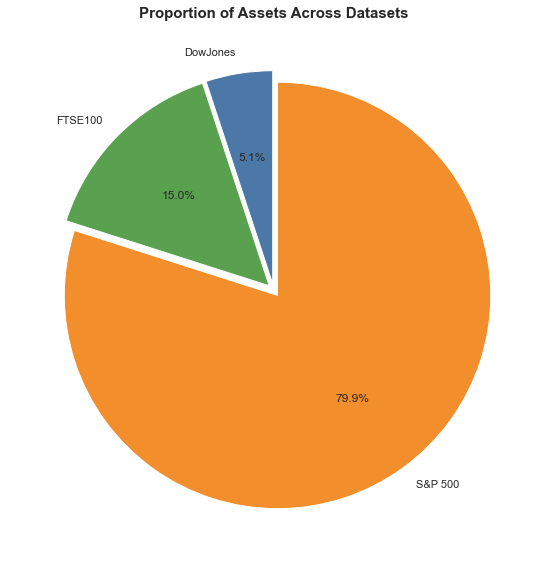

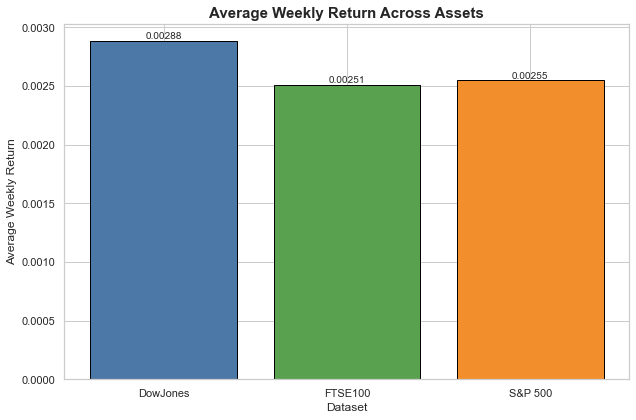

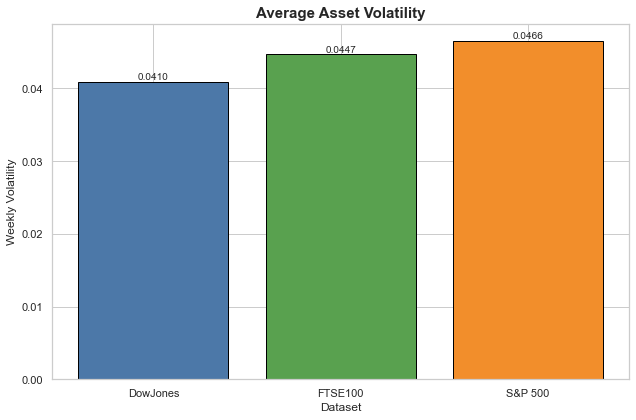

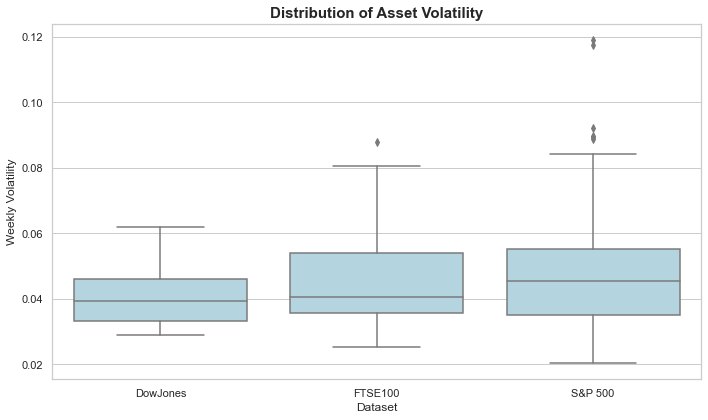

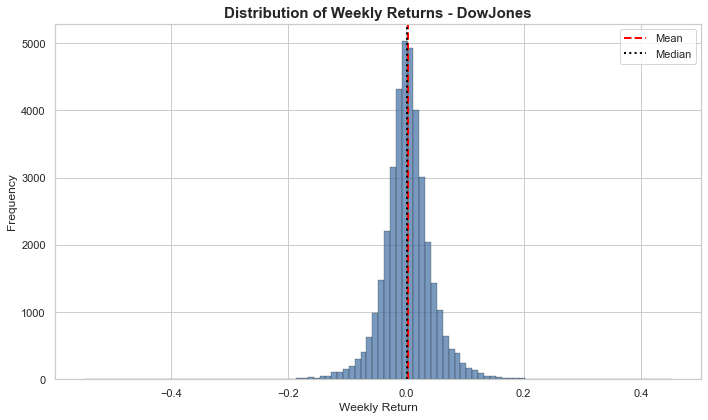

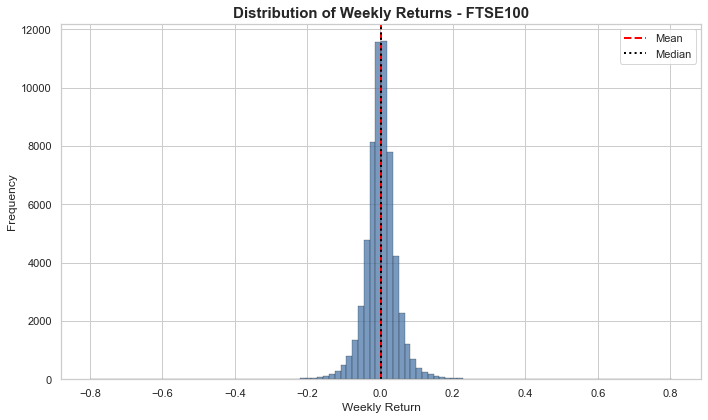

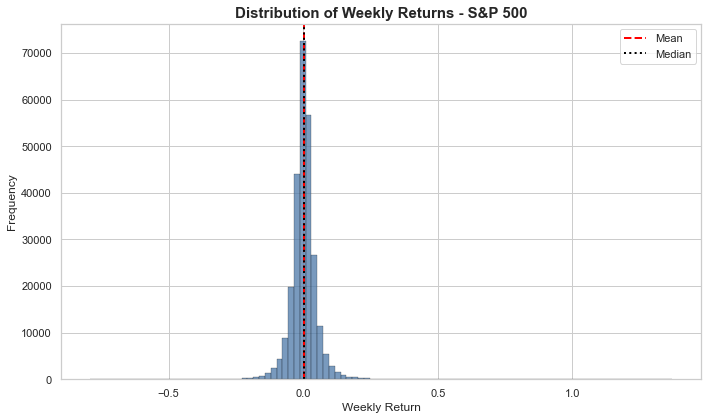

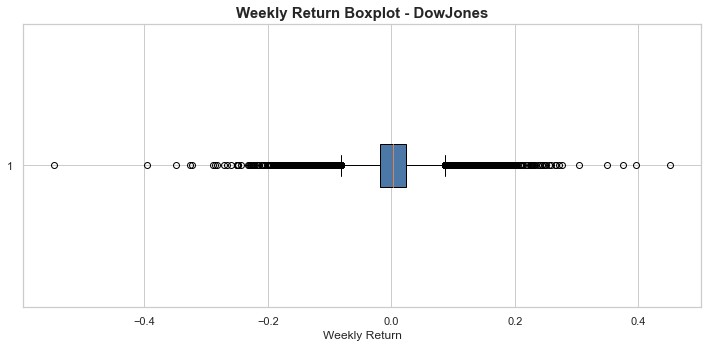

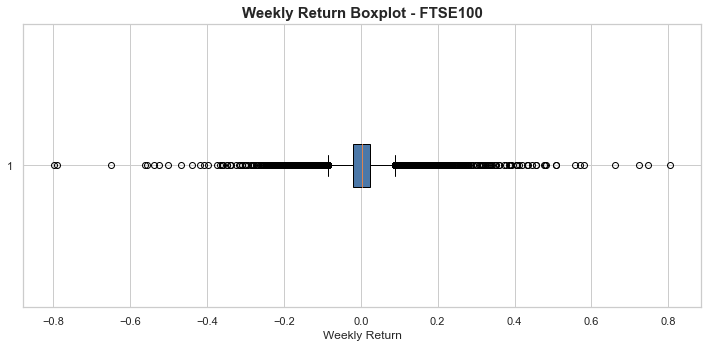

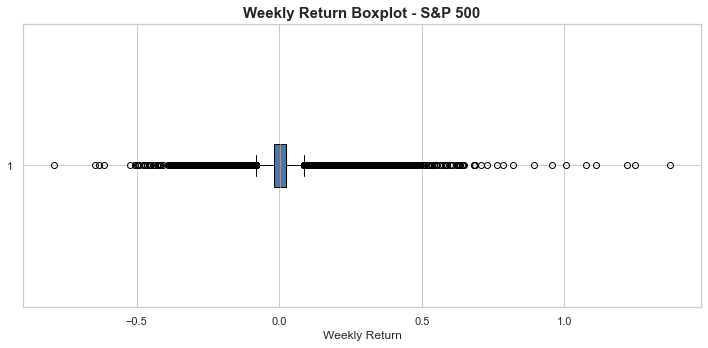



CORRELATION SUMMARY
 Dataset  Mean Correlation  Median Correlation  Minimum Correlation  Maximum Correlation
DowJones          0.336582            0.325762             0.100503             0.787045
 FTSE100          0.345084            0.338179            -0.089827             0.845918
 S&P 500          0.412351            0.406816            -0.008174             0.984175


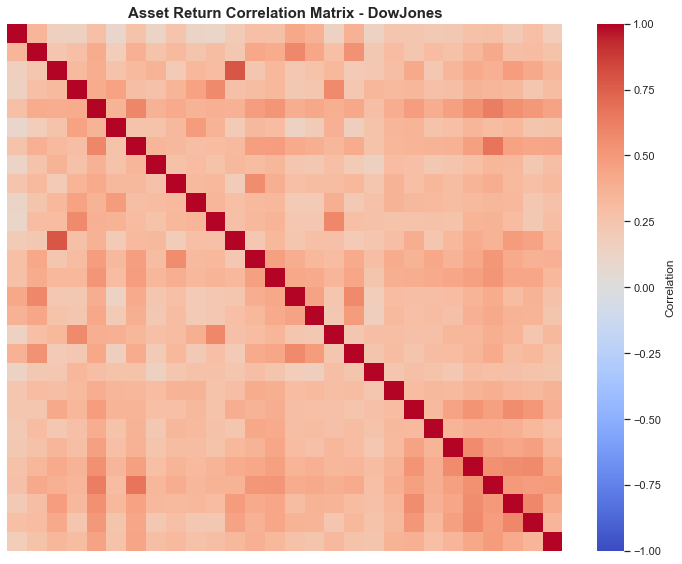

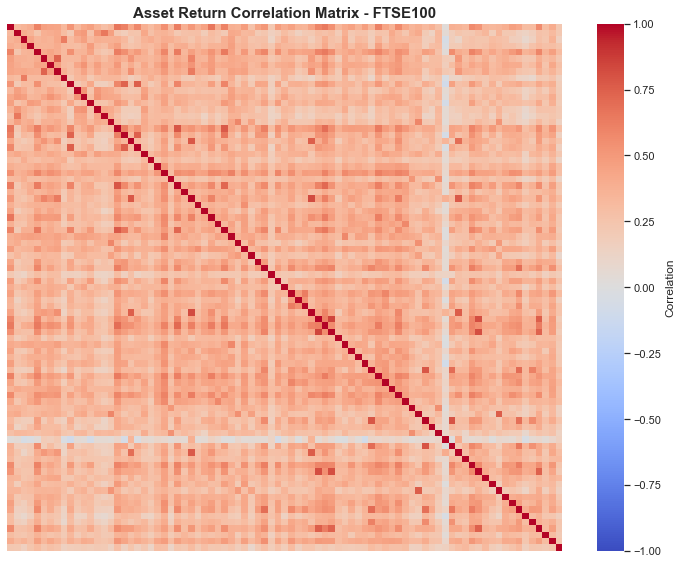

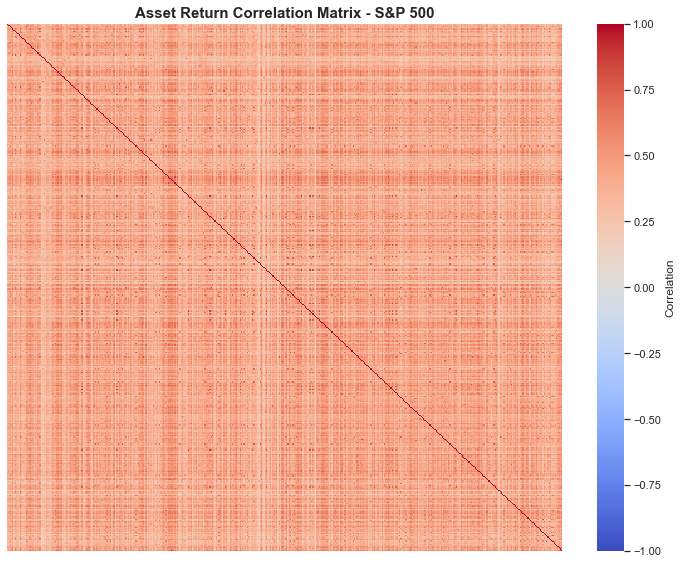

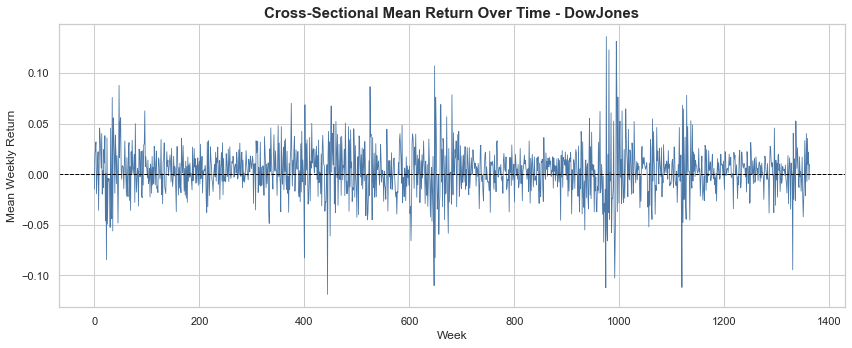

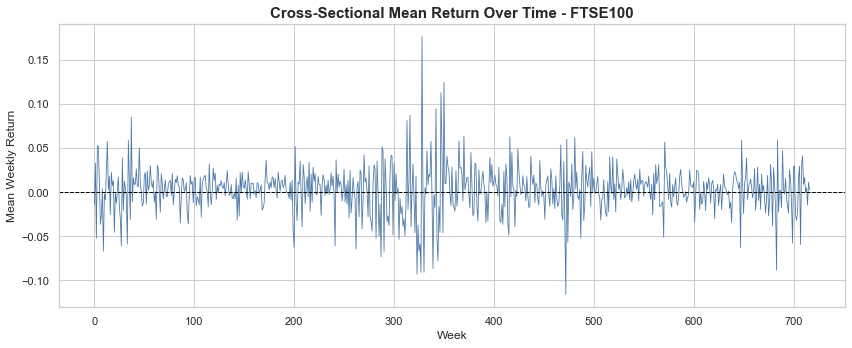

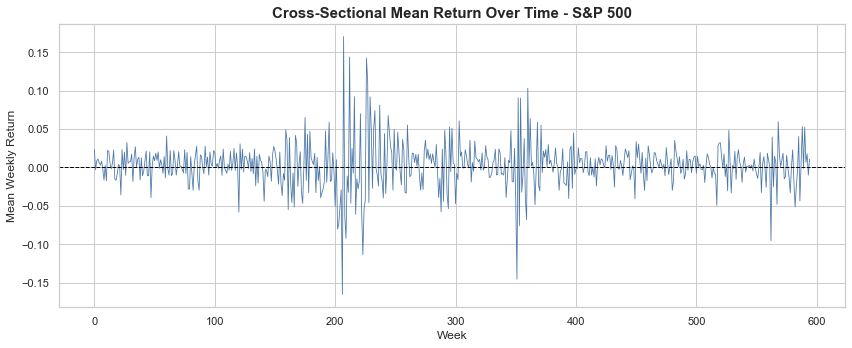

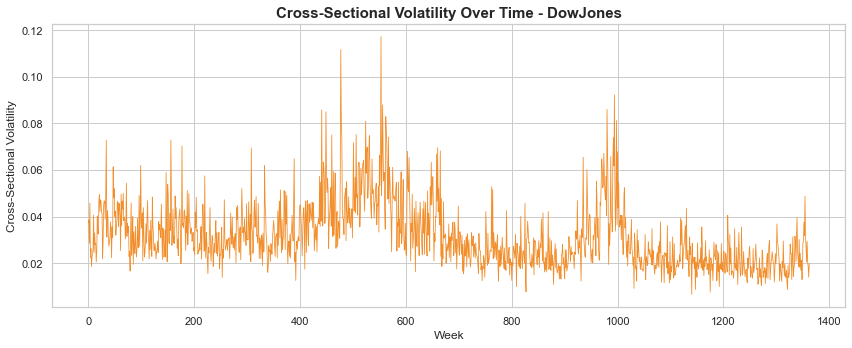

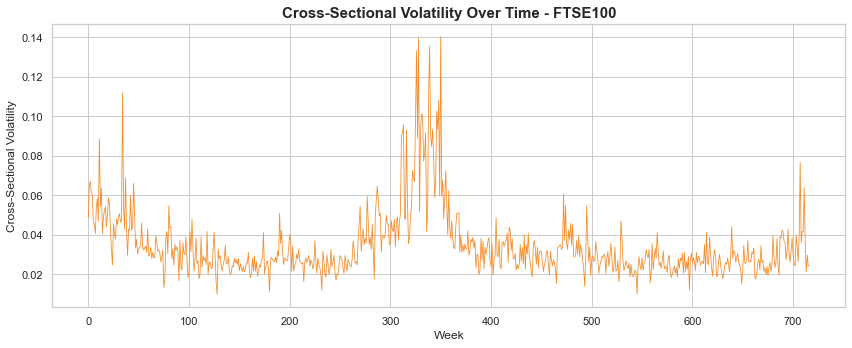

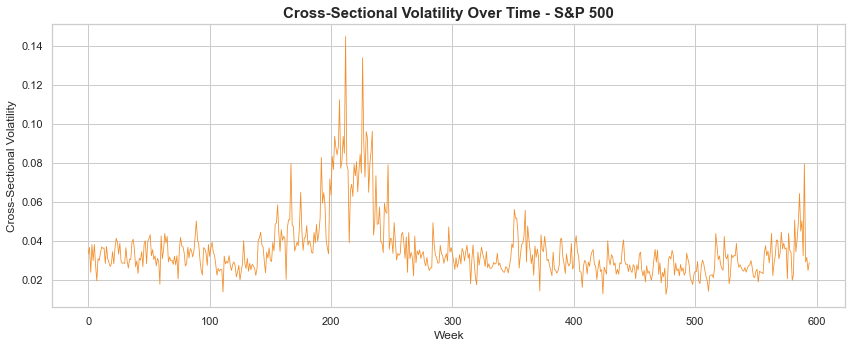

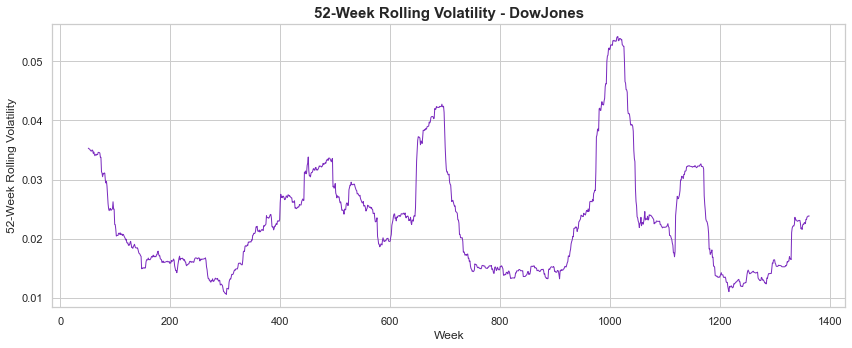

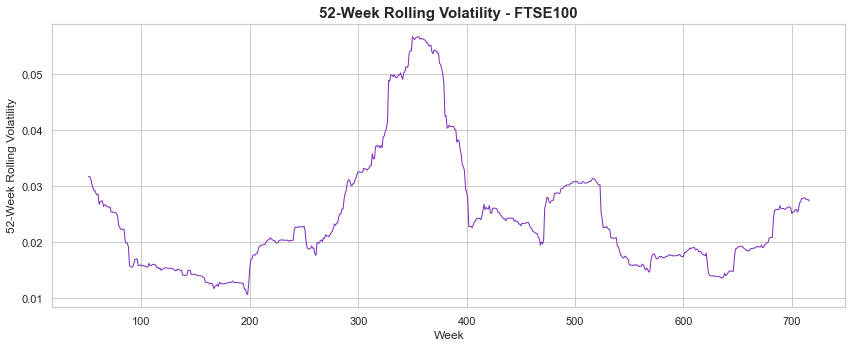

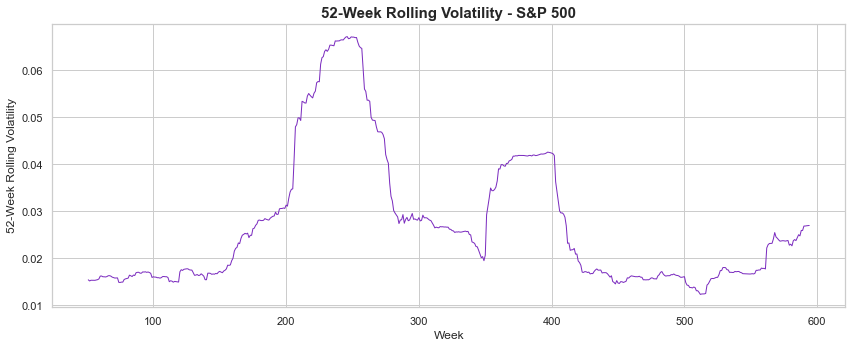

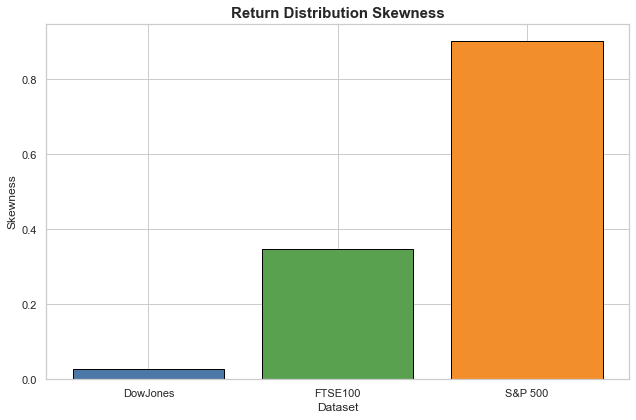

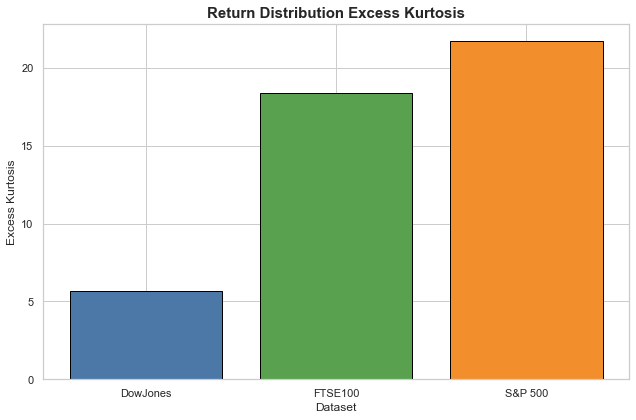



EXTREME RETURN ANALYSIS
 Dataset  1% Quantile  99% Quantile  Below 1%  Above 99%  Total Extreme
DowJones    -0.111335      0.120682       382        382            764
 FTSE100    -0.122222      0.132499       595        596           1191
 S&P 500    -0.133346      0.143753      2630       2630           5260


COVARIANCE MATRIX DIMENSIONS
 Dataset  Assets Covariance Matrix  Total Entries  Unique Pairwise Covariances
DowJones      28           28 x 28            784                          378
 FTSE100      83           83 x 83           6889                         3403
 S&P 500     442         442 x 442         195364                        97461


FINAL EDA COMPARISON
 Dataset  Assets (N)  Time Periods (T)  Total Observations  Missing Values  Mean Return  Median Return  Std Return  Minimum Return  Maximum Return  Skewness  Kurtosis  Mean Return_AssetAverage  Average Volatility  Mean Correlation  Median Correlation
DowJones          28              1363               38164       

In [ ]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis


dataset_paths = {
    "DowJones": "DowJones.xlsx",
    "FTSE100": "FTSE100.xlsx",
    "S&P 500": "SP500.xlsx"
}

# Folder for all EDA results
EDA_DIR = "eda_results"

os.makedirs(EDA_DIR, exist_ok=True)



datasets = {}

print("=" * 80)
print("LOADING DATASETS")
print("=" * 80)

for name, path in dataset_paths.items():

    data = pd.read_excel(
        path,
        sheet_name="Assets_Returns",
        header=None
    )

    # Convert everything to numeric
    data = data.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Remove completely empty rows
    data = data.dropna(
        axis=0,
        how="all"
    )

    # Remove completely empty columns
    data = data.dropna(
        axis=1,
        how="all"
    )

    # Store dataset
    datasets[name] = data

    print(f"\n{name}")
    print("-" * 50)
    print(f"Assets (N):       {data.shape[1]}")
    print(f"Time periods (T): {data.shape[0]}")
    print(f"Observations:     {data.size}")
    print(f"Missing values:   {data.isna().sum().sum()}")



summary = []

for name, data in datasets.items():

    # Combine all returns into one vector
    values = data.to_numpy().flatten()

    # Remove NaN and infinite values
    values = values[np.isfinite(values)]

    summary.append({

        "Dataset": name,

        "Assets (N)": data.shape[1],

        "Time Periods (T)": data.shape[0],

        "Total Observations": data.size,

        "Missing Values":
            int(data.isna().sum().sum()),

        "Mean Return":
            np.mean(values),

        "Median Return":
            np.median(values),

        "Std Return":
            np.std(values, ddof=1),

        "Minimum Return":
            np.min(values),

        "Maximum Return":
            np.max(values),

        "Skewness":
            skew(values),

        "Kurtosis":
            kurtosis(values)

    })


summary_df = pd.DataFrame(summary)


print("\n")
print("=" * 100)
print("DATASET SUMMARY")
print("=" * 100)

print(
    summary_df.to_string(index=False)
)


# Save
summary_df.to_csv(
    f"{EDA_DIR}/dataset_summary.csv",
    index=False
)


plt.figure(figsize=(9, 6))

x = summary_df["Dataset"]
y = summary_df["Assets (N)"]

bars = plt.bar(
    x,
    y,
    color=[
        "#4C78A8",
        "#59A14F",
        "#F28E2B"
    ],
    edgecolor="black"
)

plt.title(
    "Number of Assets in Each Dataset",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Dataset")
plt.ylabel("Number of Assets")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    f"{EDA_DIR}/number_of_assets.png",
    bbox_inches="tight"
)

plt.show()



plt.figure(figsize=(9, 6))

x = summary_df["Dataset"]
y = summary_df["Time Periods (T)"]

bars = plt.bar(
    x,
    y,
    color=[
        "#76B7B2",
        "#59A14F",
        "#E15759"
    ],
    edgecolor="black"
)

plt.title(
    "Number of Weekly Observations",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Dataset")
plt.ylabel("Number of Weekly Observations")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    f"{EDA_DIR}/number_of_time_periods.png",
    bbox_inches="tight"
)

plt.show()



asset_counts = summary_df["Assets (N)"].values
labels = summary_df["Dataset"].values

plt.figure(figsize=(8, 8))

plt.pie(
    asset_counts,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=[
        "#4C78A8",
        "#59A14F",
        "#F28E2B"
    ],
    explode=(0.03, 0.03, 0.03),
    shadow=False
)

plt.title(
    "Proportion of Assets Across Datasets",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    f"{EDA_DIR}/asset_proportions_pie.png",
    bbox_inches="tight"
)

plt.show()

asset_statistics = {}

for name, data in datasets.items():

    stats = pd.DataFrame({

        "Mean Return":
            data.mean(),

        "Median Return":
            data.median(),

        "Volatility":
            data.std(),

        "Minimum Return":
            data.min(),

        "Maximum Return":
            data.max(),

        "Skewness":
            data.skew(),

        "Kurtosis":
            data.kurtosis(),

        "Missing Values":
            data.isna().sum()

    })

    stats.index.name = "Asset"

    asset_statistics[name] = stats

    stats.to_csv(
        f"{EDA_DIR}/{name}_asset_statistics.csv"
    )


mean_returns = []

for name, data in datasets.items():

    mean_returns.append({

        "Dataset": name,

        "Mean Return":
            data.mean().mean()

    })


mean_return_df = pd.DataFrame(
    mean_returns
)


plt.figure(figsize=(9, 6))

bars = plt.bar(
    mean_return_df["Dataset"],
    mean_return_df["Mean Return"],
    color=[
        "#4C78A8",
        "#59A14F",
        "#F28E2B"
    ],
    edgecolor="black"
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Average Weekly Return Across Assets",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Dataset")
plt.ylabel("Average Weekly Return")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.5f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    f"{EDA_DIR}/mean_return_comparison.png",
    bbox_inches="tight"
)

plt.show()



volatility_results = []

for name, data in datasets.items():

    volatility_results.append({

        "Dataset": name,

        "Average Volatility":
            data.std().mean()

    })


volatility_df = pd.DataFrame(
    volatility_results
)


plt.figure(figsize=(9, 6))

bars = plt.bar(
    volatility_df["Dataset"],
    volatility_df["Average Volatility"],
    color=[
        "#4C78A8",
        "#59A14F",
        "#F28E2B"
    ],
    edgecolor="black"
)

plt.title(
    "Average Asset Volatility",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Dataset")
plt.ylabel("Weekly Volatility")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    f"{EDA_DIR}/average_volatility.png",
    bbox_inches="tight"
)

plt.show()



volatility_data = []

for name, data in datasets.items():

    for value in data.std().dropna():

        volatility_data.append({

            "Dataset": name,

            "Volatility": value

        })


volatility_box_df = pd.DataFrame(
    volatility_data
)


plt.figure(figsize=(10, 6))

sns.boxplot(
    data=volatility_box_df,
    x="Dataset",
    y="Volatility",
    color="lightblue"
)

plt.title(
    "Distribution of Asset Volatility",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Dataset")
plt.ylabel("Weekly Volatility")

plt.tight_layout()

plt.savefig(
    f"{EDA_DIR}/volatility_boxplot.png",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. RETURN DISTRIBUTIONS
# ============================================================

for name, data in datasets.items():

    values = data.to_numpy().flatten()

    values = values[
        np.isfinite(values)
    ]

    plt.figure(figsize=(10, 6))

    plt.hist(
        values,
        bins=100,
        color="#4C78A8",
        alpha=0.75,
        edgecolor="black",
        linewidth=0.3
    )

    plt.axvline(
        np.mean(values),
        color="red",
        linestyle="--",
        linewidth=2,
        label="Mean"
    )

    plt.axvline(
        np.median(values),
        color="black",
        linestyle=":",
        linewidth=2,
        label="Median"
    )

    plt.title(
        f"Distribution of Weekly Returns - {name}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Weekly Return")
    plt.ylabel("Frequency")

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        f"{EDA_DIR}/{name}_return_distribution.png",
        bbox_inches="tight"
    )

    plt.show()


for name, data in datasets.items():

    values = data.to_numpy().flatten()

    values = values[
        np.isfinite(values)
    ]

    plt.figure(figsize=(10, 5))

    plt.boxplot(
        values,
        vert=False,
        patch_artist=True,
        boxprops=dict(
            facecolor="#4C78A8"
        )
    )

    plt.title(
        f"Weekly Return Boxplot - {name}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Weekly Return")

    plt.tight_layout()

    plt.savefig(
        f"{EDA_DIR}/{name}_return_boxplot.png",
        bbox_inches="tight"
    )

    plt.show()



correlation_results = []

for name, data in datasets.items():

    corr = data.corr()

    # Save full correlation matrix
    corr.to_csv(
        f"{EDA_DIR}/{name}_correlation_matrix.csv"
    )

    # Upper triangular values
    upper_values = corr.values[
        np.triu_indices_from(
            corr.values,
            k=1
        )
    ]

    upper_values = upper_values[
        np.isfinite(upper_values)
    ]

    correlation_results.append({

        "Dataset": name,

        "Mean Correlation":
            np.mean(upper_values),

        "Median Correlation":
            np.median(upper_values),

        "Minimum Correlation":
            np.min(upper_values),

        "Maximum Correlation":
            np.max(upper_values)

    })


correlation_df = pd.DataFrame(
    correlation_results
)


print("\n")
print("=" * 100)
print("CORRELATION SUMMARY")
print("=" * 100)

print(
    correlation_df.to_string(index=False)
)


correlation_df.to_csv(
    f"{EDA_DIR}/correlation_summary.csv",
    index=False
)

for name, data in datasets.items():

    corr = data.corr()

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        corr,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={
            "label": "Correlation"
        }
    )

    plt.title(
        f"Asset Return Correlation Matrix - {name}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.savefig(
        f"{EDA_DIR}/{name}_correlation_heatmap.png",
        bbox_inches="tight"
    )

    plt.show()

for name, data in datasets.items():

    mean_return = data.mean(axis=1)

    plt.figure(figsize=(12, 5))

    plt.plot(
        mean_return,
        color="#4C78A8",
        linewidth=0.8
    )

    plt.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    plt.title(
        f"Cross-Sectional Mean Return Over Time - {name}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Week")
    plt.ylabel("Mean Weekly Return")

    plt.tight_layout()

    plt.savefig(
        f"{EDA_DIR}/{name}_mean_return_time_series.png",
        bbox_inches="tight"
    )

    plt.show()



for name, data in datasets.items():

    cross_sectional_volatility = data.std(axis=1)

    plt.figure(figsize=(12, 5))

    plt.plot(
        cross_sectional_volatility,
        color="#F28E2B",
        linewidth=0.8
    )

    plt.title(
        f"Cross-Sectional Volatility Over Time - {name}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Week")
    plt.ylabel("Cross-Sectional Volatility")

    plt.tight_layout()

    plt.savefig(
        f"{EDA_DIR}/{name}_cross_sectional_volatility.png",
        bbox_inches="tight"
    )

    plt.show()



for name, data in datasets.items():

    mean_return = data.mean(axis=1)

    rolling_volatility = (
        mean_return
        .rolling(window=52)
        .std()
    )

    plt.figure(figsize=(12, 5))

    plt.plot(
        rolling_volatility,
        color="#7B2CBF",
        linewidth=1
    )

    plt.title(
        f"52-Week Rolling Volatility - {name}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Week")
    plt.ylabel("52-Week Rolling Volatility")

    plt.tight_layout()

    plt.savefig(
        f"{EDA_DIR}/{name}_rolling_volatility.png",
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 16. SKEWNESS AND KURTOSIS COMPARISON
# ============================================================

shape_summary = []

for name, data in datasets.items():

    values = data.to_numpy().flatten()

    values = values[
        np.isfinite(values)
    ]

    shape_summary.append({

        "Dataset": name,

        "Skewness": skew(values),

        "Kurtosis": kurtosis(values)

    })


shape_df = pd.DataFrame(
    shape_summary
)


# ------------------------------------------------------------
# Skewness
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

bars = plt.bar(
    shape_df["Dataset"],
    shape_df["Skewness"],
    color=[
        "#4C78A8",
        "#59A14F",
        "#F28E2B"
    ],
    edgecolor="black"
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Return Distribution Skewness",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Dataset")
plt.ylabel("Skewness")

plt.tight_layout()

plt.savefig(
    f"{EDA_DIR}/skewness_comparison.png",
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Kurtosis
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

bars = plt.bar(
    shape_df["Dataset"],
    shape_df["Kurtosis"],
    color=[
        "#4C78A8",
        "#59A14F",
        "#F28E2B"
    ],
    edgecolor="black"
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Return Distribution Excess Kurtosis",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Dataset")
plt.ylabel("Excess Kurtosis")

plt.tight_layout()

plt.savefig(
    f"{EDA_DIR}/kurtosis_comparison.png",
    bbox_inches="tight"
)

plt.show()


extreme_results = []

for name, data in datasets.items():

    values = data.to_numpy().flatten()

    values = values[
        np.isfinite(values)
    ]

    lower = np.quantile(
        values,
        0.01
    )

    upper = np.quantile(
        values,
        0.99
    )

    below = np.sum(
        values < lower
    )

    above = np.sum(
        values > upper
    )

    extreme_results.append({

        "Dataset": name,

        "1% Quantile": lower,

        "99% Quantile": upper,

        "Below 1%": below,

        "Above 99%": above,

        "Total Extreme": below + above

    })


extreme_df = pd.DataFrame(
    extreme_results
)


print("\n")
print("=" * 100)
print("EXTREME RETURN ANALYSIS")
print("=" * 100)

print(
    extreme_df.to_string(index=False)
)


extreme_df.to_csv(
    f"{EDA_DIR}/extreme_returns.csv",
    index=False
)


covariance_results = []

for name, data in datasets.items():

    N = data.shape[1]

    covariance_results.append({

        "Dataset": name,

        "Assets": N,

        "Covariance Matrix":
            f"{N} x {N}",

        "Total Entries":
            N ** 2,

        "Unique Pairwise Covariances":
            N * (N - 1) // 2

    })


covariance_df = pd.DataFrame(
    covariance_results
)


print("\n")
print("=" * 100)
print("COVARIANCE MATRIX DIMENSIONS")
print("=" * 100)

print(
    covariance_df.to_string(index=False)
)


covariance_df.to_csv(
    f"{EDA_DIR}/covariance_summary.csv",
    index=False
)



final_summary = summary_df.copy()

final_summary = final_summary.merge(
    mean_return_df,
    on="Dataset",
    suffixes=("", "_AssetAverage")
)

final_summary = final_summary.merge(
    volatility_df,
    on="Dataset"
)

final_summary = final_summary.merge(
    correlation_df[
        [
            "Dataset",
            "Mean Correlation",
            "Median Correlation"
        ]
    ],
    on="Dataset"
)


print("\n")
print("=" * 120)
print("FINAL EDA COMPARISON")
print("=" * 120)

print(
    final_summary.to_string(index=False)
)


final_summary.to_csv(
    f"{EDA_DIR}/final_eda_summary.csv",
    index=False
)

print("\n")
print("=" * 80)
print("EDA COMPLETE")
print("=" * 80)

print(
    f"All tables and figures have been saved to: {EDA_DIR}/"
)

